# Gaussian samples and confidence ellipsoids

Let $X=(X_1,X_2)$ be a zero-mean Gaussian random vector with covariance
$$
\Sigma = \begin{bmatrix} 3 & -2 \\ -2 & 5 \end{bmatrix}
$$
With a negative value of $\Sigma_{12}$, it shows that $X_1$ is anti-correlated with $X_2$ ($X_1$ increases, but $X_2$ decreases such as altitude vs temperature ).

Key math concepts (You will learn this in more advanced math course):
1. The region of Gaussian samples has an **ellipsoid** shape. The confidence region is parametrized by ellipsoid equation.
2. The direction of the ellipsoid's principal axes is determined by **the eigenvector** of $\Sigma$.
3. The length of the principal axes is proportional to the **eigenvalues** of $\Sigma$.

<>:37: SyntaxWarning: invalid escape sequence '\S'
<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\S'
<>:37: SyntaxWarning: invalid escape sequence '\S'
<>:37: SyntaxWarning: invalid escape sequence '\l'
<>:46: SyntaxWarning: invalid escape sequence '\S'
/tmp/ipython-input-358341882.py:37: SyntaxWarning: invalid escape sequence '\S'
  label=f'Ellipsoid ($x^T \Sigma^{{-1}} x \leq {alpha}$)')
/tmp/ipython-input-358341882.py:37: SyntaxWarning: invalid escape sequence '\l'
  label=f'Ellipsoid ($x^T \Sigma^{{-1}} x \leq {alpha}$)')
/tmp/ipython-input-358341882.py:46: SyntaxWarning: invalid escape sequence '\S'
  plt.title(f"Gaussian Distribution & Confidence Ellipsoid\n$\Sigma = [[2, -1], [-1, 4]]$")


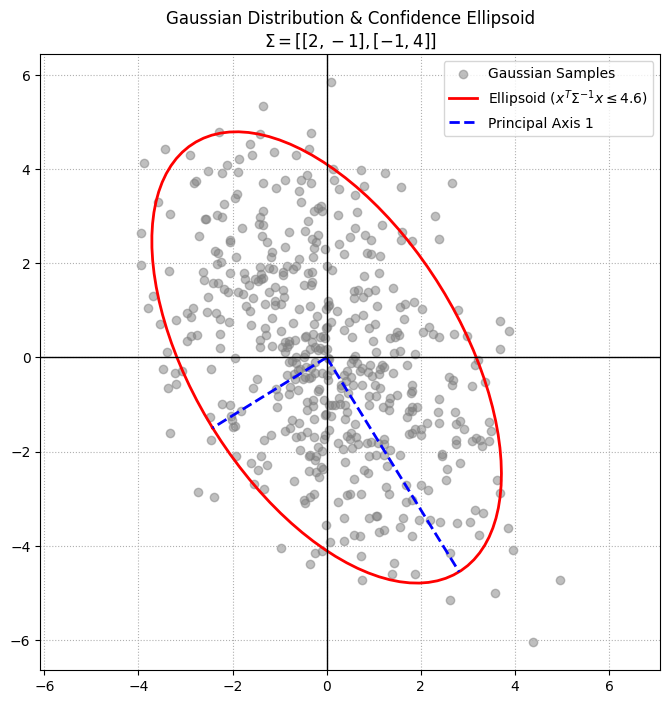

Eigenvalues: [1.76393202 6.23606798]
Full Length of Principal Axis 1: 5.6970
Full Length of Principal Axis 2: 10.7118


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Given parameters
Sigma = np.array([[3, -2], [-2, 5]])
N = 500
alpha = 4.6  # User-specified threshold

# 1) Generate Gaussian samples (Mean = 0)
mean = [0, 0]
X = np.random.multivariate_normal(mean, Sigma, N)

# 4) Calculate eigenvalues and eigenvectors for the ellipsoid geometry
eigenvalues, eigenvectors = np.linalg.eig(Sigma)

# The lengths of the principal axes (full length) are 2 * sqrt(alpha * eigenvalue)
axis_lengths = 2 * np.sqrt(alpha * eigenvalues)

# 3) Generate the ellipsoid boundary points
theta = np.linspace(0, 2*np.pi, 100)
unit_circle = np.array([np.cos(theta), np.sin(theta)])

# Transform unit circle to ellipsoid: x = sqrt(alpha) * R * sqrt(Lambda) * unit_circle
# where R is the eigenvector matrix and Lambda is the eigenvalue matrix
rotation = eigenvectors
scaling = np.diag(np.sqrt(eigenvalues))
ellipsoid_points = rotation @ scaling @ (np.sqrt(alpha) * unit_circle)

# 2) Plotting
plt.figure(figsize=(8, 8))

# Plot Gaussian samples
plt.scatter(X[:, 0], X[:, 1], alpha=0.5, label='Gaussian Samples', color='gray')

# Plot Ellipsoid boundary
plt.plot(ellipsoid_points[0, :], ellipsoid_points[1, :], 'r-', lw=2,
         label=f'Ellipsoid ($x^T \Sigma^{{-1}} x \leq {alpha}$)')

# Draw Principal Axes (Semi-axes)
for i in range(2):
    direction = eigenvectors[:, i] * np.sqrt(alpha * eigenvalues[i])
    plt.plot([0, direction[0]], [0, direction[1]], color='blue', lw=2, linestyle='--',
             label=f'Principal Axis {i+1}' if i==0 else "")

plt.axhline(0, color='black', lw=1); plt.axvline(0, color='black', lw=1)
plt.title(f"Gaussian Distribution & Confidence Ellipsoid\n$\Sigma = [[2, -1], [-1, 4]]$")
plt.legend()
plt.axis('equal')
plt.grid(True, linestyle=':')
plt.show()

print(f"Eigenvalues: {eigenvalues}")
print(f"Full Length of Principal Axis 1: {axis_lengths[0]:.4f}")
print(f"Full Length of Principal Axis 2: {axis_lengths[1]:.4f}")

# Matrix exponential $e^{At}$

A continuous-time linear state-space system $\dot{x} = Ax$ has a solution of $x(t) = e^{At}x(0)$.

$e^{At}$ can be computed using `scipy.linalg.expm`.

In fact, solving ODE numericallly requires ODE solver. This notebooks just illustrates the computation using the matrix exponential.

Input: $A \in \mathbf{R}^{n \times n}, x(0) \in \mathbf{R}^n$, and $T > 0$ (the final time of simulation).

Output: $x(t)$ for $t \in [0,T]$ and vector $t$.

Students can
1) Observe the behaviour of $x(t)$ as $A$ changes.
2) How to explain the shape of $x(t)$ associated with $A$? eigenvalues?

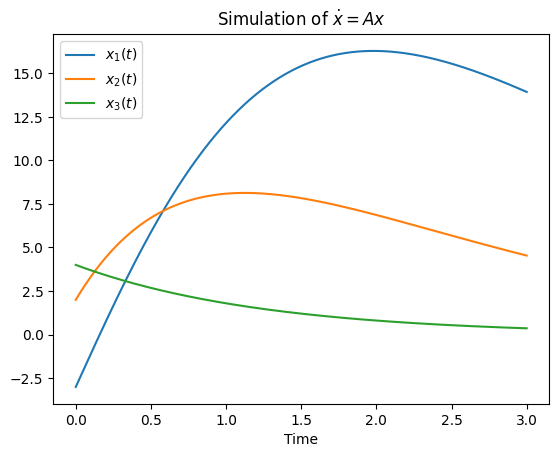

In [20]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt

def sim_cont_statespace(A,x0,T):

  d,V = np.linalg.eig(A)
  N = 1000  # simulate 1000 points
  t = np.linspace(0,T,N)

  state_list= []
  for k in range(len(t)):
      expAt = sp.linalg.expm(t[k]*A)
      xt = expAt@x0
      state_list.append(xt)
  return t, state_list

# Try several A and x0
# A = np.array([[-1,1],[0,-0.5]])
# x0 = np.array([-4,2])

A = np.array([[-1,2,3],[0,-0.8,4],[0,0,-0.8]])
x0 = np.array([-3,2,4])

n = np.shape(A)[0]
T = 3
t, state_list = sim_cont_statespace(A,x0,T)

data = np.array(state_list)

for k in range(n):
  plt.plot(t, data[:,k] , label = f"$x_{k+1}(t)$")
  plt.xlabel('Time')
  plt.title(r'Simulation of $\dot{x} = Ax$')
  plt.legend()